# Fashion-MNIST specialist → stacked Multi-Fashion-MNIST generalist
**Specialist (ResNet18) → soft labels → Generalist (ResNet50), with Pareto exploration/expansion and LS / PCGrad / MGDA / FAMO.**

This is a dataset adaptation of the supplied MultiDigitMNIST notebook. The *specialist* classifies one Fashion-MNIST item at a time. The *generalist* receives a **single, overlapping two-item Fashion-MNIST composite** and predicts the category of the top-left and bottom-right item with two task heads.

**Dataset provenance (GitHub)**
- Original Fashion-MNIST: https://github.com/zalandoresearch/fashion-mnist
- Multi-Fashion-MNIST implementation/benchmark (`mf`; different from Fashion+MNIST, `mfm`): https://github.com/ruchtem/cosmos
- Additional related implementation and benchmarking caveat: https://github.com/ruchtem/moo-mtl

**Important:** This notebook generates its own *Multi-Fashion-MNIST-style* synthetic composites reproducibly from `torchvision.datasets.FashionMNIST`. It **does not load the exact precomputed images/splits** in these GitHub repositories. Each composite has two 28×28 item images at `(0,0)` and `(8,8)` on a **36×36** canvas with additive, clipped overlay. This matches the benchmark's basic geometry but does not establish numerical comparability with published runs.

**Workflow**
1. Train a 2-objective specialist on clean single clothing items and challenging overlapping-item crops. Select a checkpoint **using validation errors**, never test errors.
2. Generate specialist soft targets for the two positions on training composites (teacher is given true crop positions during *training only*).
3. Train a 2-head generalist end-to-end on the **full stacked image** using semi-supervised knowledge distillation. Explore and expand validation Pareto candidates across LS, PCGrad, MGDA, FAMO.
4. Select a generalist by validation error and report test error only after selection. Models are **retrained deterministically** for the final test evaluation to avoid retaining many large ResNet50 state dictionaries.

> **Research caution:** Multi-task benchmarks can have few genuine conflicting objectives, so a non-dominated set here is not proof of a meaningful Pareto trade-off. See Ruchte & Grabocka, *Multi-task problems are not multi-objective* (https://github.com/ruchtem/moo-mtl).

In [ ]:
# Optional: !pip install torch torchvision matplotlib numpy pandas
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, matplotlib.pyplot as plt, random, time, copy
from torchvision import datasets, models

import pandas as pd


In [2]:
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', dev)

device: cuda


In [3]:
CFG = dict(
    N_TRAIN_MULTI = 20000,   # composed train images (mostly pseudo-labeled)
    N_VAL_MULTI   = 2000,    # generated from the 6k-item held-out Fashion train/val pool
    N_TEST_MULTI  = 5000,    # generated only from the original Fashion-MNIST test pool
    N_SPEC_HARD   = 20000,   # overlapped single-item crops for specialist
    LABELED_FRAC  = 0.05,    # composite training images retaining hard labels
    BS = 128, LR = 1e-3,
    SPEC_EPOCHS = 3, GEN_EPOCHS = 4,
    T_KD = 2.0,
    LAM = 0.7,               # KD share, vs labeled-only CE
    METHODS = ['ls', 'pcgrad', 'mgda', 'famo'],
    N_PREF_EXTRA = 0,
    EXPAND_ROUNDS = 1,
    SEED = 0,
)
# QUICK SMOKE TEST (uncomment BEFORE running any dataset cells):
# CFG.update(N_TRAIN_MULTI=256, N_VAL_MULTI=64, N_TEST_MULTI=64,
#            N_SPEC_HARD=256, BS=16, SPEC_EPOCHS=1, GEN_EPOCHS=1,
#            METHODS=['ls'], EXPAND_ROUNDS=0)
# Full default config is compute-intensive. CUDA GPU is strongly recommended.

In [4]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])

## 1. Data: individual Fashion-MNIST items and two-item stacked Multi-Fashion-MNIST
**Task 0:** recognize the top-left item. **Task 1:** recognize the bottom-right item. Both tasks have the same 10 Fashion-MNIST classes.

To avoid validation/test leakage, the 60k Fashion-MNIST training items are first split (54k source-train / 6k source-validation), **before any stacking**. The 10k official test items are used exclusively to generate the composite test set.

In [5]:
CANVAS, DS, K = 36, 28, 2
SLOT_POS = ((0, 0), (8, 8))  # (y, x) top-left and bottom-right; heavy overlap
CLASS_NAMES = ('T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot')

In [6]:
fashion_tr = datasets.FashionMNIST('./data', train=True, download=True)
fashion_te = datasets.FashionMNIST('./data', train=False, download=True)
all_tr_x, all_tr_y = fashion_tr.data.numpy(), fashion_tr.targets.numpy()
fa_te_x, fa_te_y = fashion_te.data.numpy(), fashion_te.targets.numpy()

100%|██████████| 26.4M/26.4M [00:15<00:00, 1.72MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 154kB/s]
100%|██████████| 4.42M/4.42M [00:04<00:00, 936kB/s] 
100%|██████████| 5.15k/5.15k [00:00<00:00, 42.9MB/s]


In [7]:
split_rng = np.random.RandomState(CFG['SEED'])
perm = split_rng.permutation(len(all_tr_x))
train_ids, val_ids = perm[:54000], perm[54000:]
fa_tr_x, fa_tr_y = all_tr_x[train_ids], all_tr_y[train_ids]
fa_val_x, fa_val_y = all_tr_x[val_ids], all_tr_y[val_ids]

In [8]:
def make_multi(imgs, labels, n, seed):
    """Synthesize a two-task Multi-Fashion-MNIST-style *overlapping* 36x36 set.
    X: uint8 (n, 36, 36), Y: long (n, 2), P: crop coordinates (n, 2, 2).
    Use saturating additive overlay (not concatenation, not RGB channel stacking).
    """
    rng = np.random.RandomState(seed)
    X = np.zeros((n, CANVAS, CANVAS), dtype=np.uint8)
    Y = np.zeros((n, K), dtype=np.int64)
    P = np.broadcast_to(np.asarray(SLOT_POS, np.int64), (n, K, 2)).copy()
    for i in range(n):
        idx = rng.randint(0, len(imgs), size=K)
        for k, j in enumerate(idx):
            y, x = SLOT_POS[k]
            patch = X[i, y:y+DS, x:x+DS].astype(np.uint16) + imgs[j].astype(np.uint16)
            X[i, y:y+DS, x:x+DS] = np.minimum(patch, 255).astype(np.uint8)
            Y[i, k] = labels[j]
    return X, Y, P

In [9]:
def crop_pad(X, P, k):
    """Oracle crop of item k from a composite, centered on another 36x36 canvas.
    Neighboring-item pixels inside the crop remain visible by design.
    """
    out = np.zeros_like(X)
    off = (CANVAS - DS) // 2
    for i in range(len(X)):
        y, x = P[i, k]
        out[i, off:off+DS, off:off+DS] = X[i, y:y+DS, x:x+DS]
    return out

In [10]:
def pad_fashion(imgs):
    out = np.zeros((len(imgs), CANVAS, CANVAS), np.uint8)
    off = (CANVAS - DS) // 2
    out[:, off:off+DS, off:off+DS] = imgs
    return out

In [11]:
# Composite sets: independently sampled from non-overlapping source pools.
Xg_tr,  Yg_tr,  Pg_tr  = make_multi(fa_tr_x,  fa_tr_y,  CFG['N_TRAIN_MULTI'], seed=1)
Xg_val, Yg_val, Pg_val = make_multi(fa_val_x, fa_val_y, CFG['N_VAL_MULTI'],   seed=2)
Xg_te,  Yg_te,  Pg_te  = make_multi(fa_te_x,  fa_te_y,  CFG['N_TEST_MULTI'],  seed=3)

In [12]:
# Specialist objective 0: clean padded items.
Xs_c, Ys_c = pad_fashion(fa_tr_x), fa_tr_y
# Specialist objective 1: crops of stacked items with overlapping distractors.
n_h = (CFG['N_SPEC_HARD'] + K - 1) // K
Xh_raw, Yh_raw, Ph_raw = make_multi(fa_tr_x, fa_tr_y, n_h, seed=4)
Xs_h = np.concatenate([crop_pad(Xh_raw, Ph_raw, k) for k in range(K)])[:CFG['N_SPEC_HARD']]
Ys_h = np.concatenate([Yh_raw[:, k] for k in range(K)])[:CFG['N_SPEC_HARD']]
nS = min(len(Xs_c), len(Xs_h))
Xs_c, Ys_c, Xs_h, Ys_h = Xs_c[:nS], Ys_c[:nS], Xs_h[:nS], Ys_h[:nS]

In [13]:
# Specialist validation and test sets (used only at their corresponding stages).
Xs_c_val, Ys_c_val = pad_fashion(fa_val_x), fa_val_y
Xs_h_val = np.concatenate([crop_pad(Xg_val, Pg_val, k) for k in range(K)])
Ys_h_val = np.concatenate([Yg_val[:, k] for k in range(K)])
Xs_c_te, Ys_c_te = pad_fashion(fa_te_x), fa_te_y
Xs_h_te = np.concatenate([crop_pad(Xg_te, Pg_te, k) for k in range(K)])
Ys_h_te = np.concatenate([Yg_te[:, k] for k in range(K)])

In [14]:
# Keep uint8 images until a minibatch is actually normalized.
def as_dev(a):
    return torch.from_numpy(np.ascontiguousarray(a)).to(dev)

In [15]:
Xg_tr_t, Yg_tr_t = as_dev(Xg_tr), as_dev(Yg_tr)
Xg_val_t, Yg_val_t = as_dev(Xg_val), as_dev(Yg_val)
Xg_te_t, Yg_te_t = as_dev(Xg_te), as_dev(Yg_te)
Xs_c_t, Ys_c_t, Xs_h_t, Ys_h_t = map(as_dev, (Xs_c, Ys_c, Xs_h, Ys_h))
Xs_c_val_t, Ys_c_val_t, Xs_h_val_t, Ys_h_val_t = map(as_dev, (Xs_c_val, Ys_c_val, Xs_h_val, Ys_h_val))
Xs_c_te_t, Ys_c_te_t, Xs_h_te_t, Ys_h_te_t = map(as_dev, (Xs_c_te, Ys_c_te, Xs_h_te, Ys_h_te))

In [16]:
assert Xg_tr.shape[1:] == (36, 36) and Yg_tr.shape[1] == K
assert Xs_c.shape[1:] == (36, 36) and len(Xs_c) == len(Xs_h)
print(f'Fashion source pools: train={len(fa_tr_x)}, val={len(fa_val_x)}, test={len(fa_te_x)}')
print(f'Composites: train={len(Xg_tr)}, val={len(Xg_val)}, test={len(Xg_te)}')

Fashion source pools: train=54000, val=6000, test=10000
Composites: train=20000, val=2000, test=5000


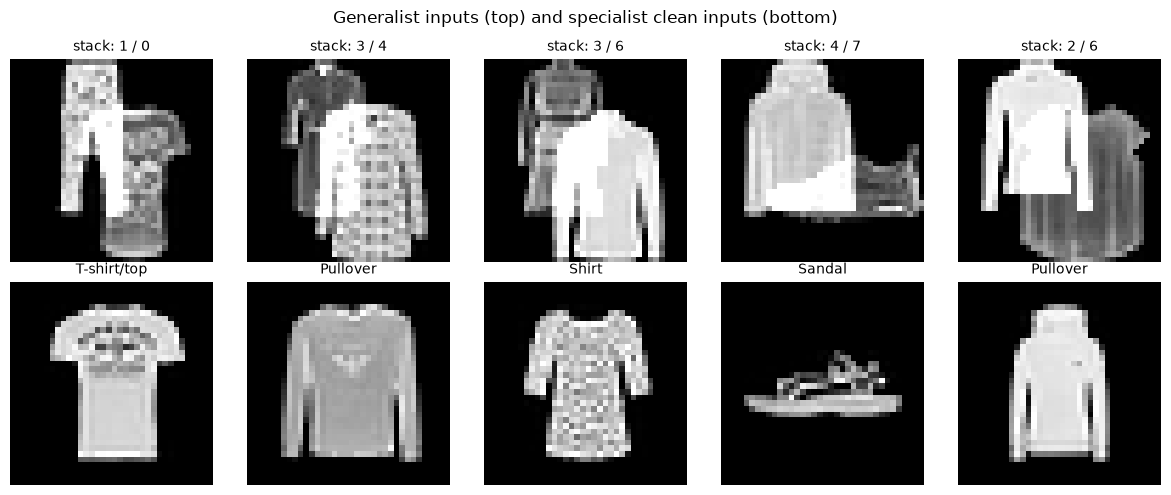

In [17]:
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    ax[0, i].imshow(Xg_tr[i], cmap='gray', vmin=0, vmax=255)
    ax[0, i].set_title(f'stack: {Yg_tr[i,0]} / {Yg_tr[i,1]}', fontsize=10)
    ax[0, i].axis('off')
    ax[1, i].imshow(Xs_c[i], cmap='gray', vmin=0, vmax=255)
    ax[1, i].set_title(CLASS_NAMES[Ys_c[i]], fontsize=10)
    ax[1, i].axis('off')
plt.suptitle('Generalist inputs (top) and specialist clean inputs (bottom)')
plt.tight_layout(); plt.show()

## 2. Models (ResNet18 specialist / ResNet50 generalist)
Both networks use a single grayscale input channel. For the 36×36 canvases, use a 3×3 stride-1 stem (and no initial max pool) so small clothing details are not lost immediately. The generalist has a shared backbone and two classification heads.

In [18]:
class MTLNet(nn.Module):
    def __init__(self, arch, n_heads, n_cls=10):
        super().__init__()
        bb = getattr(models, arch)(weights=None)
        bb.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        bb.maxpool = nn.Identity()
        feat = bb.fc.in_features
        bb.fc = nn.Identity()
        self.backbone = bb
        self.heads = nn.ModuleList([nn.Linear(feat, n_cls) for _ in range(n_heads)])

    def forward(self, x):
        f = self.backbone(x)
        return [head(f) for head in self.heads]


In [19]:
def prep(xb, shift=0):
    x = xb.float().div(255).unsqueeze(1)
    # Augment without circular roll/wraparound (which corrupts fixed slot positions).
    if shift:
        sy = random.randint(-shift, shift)
        sx = random.randint(-shift, shift)
        x = F.pad(x, (shift, shift, shift, shift))
        x = x[:, :, shift + sy:shift + sy + CANVAS,
                  shift + sx:shift + sx + CANVAS]
    return x

In [20]:
@torch.no_grad()
def predict(model, X, bs=512, temp=1.0):
    model.eval(); outs = None
    for s in range(0, len(X), bs):
        o = model(prep(X[s:s+bs]))
        o = [F.softmax(z / temp, dim=-1).cpu() for z in o]
        outs = [[a] for a in o] if outs is None else [p + [a] for p, a in zip(outs, o)]
    return [torch.cat(p) for p in outs]

## 3. Multi-objective gradient methods: LS, PCGrad, MGDA, FAMO
These operate on the **shared backbone** gradients; task-head gradients remain task-specific. The preference vector reweights task objectives; actual distinct compromises are **not guaranteed** in a high-capacity multi-task network.

In [21]:
def flat_grads(losses, params):
    gs = []
    for l in losses:
        g = torch.autograd.grad(l, params, retain_graph=True, allow_unused=True)
        gs.append(torch.cat([(gi if gi is not None else torch.zeros_like(p)).flatten() for gi, p in zip(g, params)]))
    return torch.stack(gs)                                   # (T, P)

In [22]:
def pcgrad(G):
    # project each task gradient away from conflicting ones (Yu et al. 2020)
    T = len(G); out = G.clone()
    for i in range(T):
        for j in random.sample(range(T), T):
            if j == i: continue
            dot = (out[i] * G[j]).sum()
            if dot < 0: out[i] = out[i] - dot / (G[j].norm() ** 2 + 1e-12) * G[j]
    return out.sum(0)

In [23]:
def mgda_weights(G, iters=50):
    # min-norm point in the convex hull of task gradients (Desideri 2012; Sener & Koltun 2018), Frank-Wolfe solver
    M = G @ G.T; T = len(G); a = torch.ones(T, device=G.device) / T
    for _ in range(iters):
        i = torch.argmin(M @ a); e = torch.zeros_like(a); e[i] = 1; d = e - a
        gamma = torch.clamp(-(d @ M @ a) / (d @ M @ d + 1e-12), 0, 1)
        a = a + gamma * d
    return a

In [24]:
class FAMO:
    # Fast Adaptive Multitask Optimization (Liu et al. 2023): O(1) space/time, balances rate of loss decrease
    def __init__(self, T, pref=None, lr=0.025, gamma=1e-3):
        init = torch.log(torch.tensor(pref if pref is not None else [1.0 / T] * T, dtype=torch.float32))
        self.w = init.clone().to(dev).requires_grad_(True)
        self.opt = torch.optim.Adam([self.w], lr=lr, weight_decay=gamma); self.eps = 1e-8
        self.min_loss = torch.zeros(T, device=dev)
    def weighted(self, losses):
        D = losses - self.min_loss + self.eps; z = F.softmax(self.w, -1); c = (z / D).sum().detach()
        return (D.log() * z / c).sum()
    def update(self, prev, curr):
        delta = (prev - self.min_loss + self.eps).log() - (curr - self.min_loss + self.eps).log()
        with torch.enable_grad():
            d = torch.autograd.grad(F.softmax(self.w, -1), self.w, grad_outputs=delta.detach())[0]
        self.opt.zero_grad(); self.w.grad = d; self.opt.step()

In [25]:
def train_mtl(model, loss_fn, n_train, T, method, pref, epochs, lr=None, bs=None):
    lr = lr or CFG['LR']; bs = bs or CFG['BS']
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * (n_train // bs); sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps)
    shared = list(model.backbone.parameters()); pref_t = torch.tensor(pref, device=dev, dtype=torch.float32) * T
    famo = FAMO(T, pref) if method == 'famo' else None
    for ep in range(epochs):
        model.train(); perm = torch.randperm(n_train, device=dev)
        for s in range(0, n_train - bs + 1, bs):
            idx = perm[s:s+bs]; losses = loss_fn(model, idx); opt.zero_grad()
            if method == 'ls':
                sum(pref_t[i] * losses[i] for i in range(T)).backward()
            elif method == 'famo':
                famo.weighted(torch.stack(losses)).backward()
            else:   # pcgrad / mgda
                wl = [pref_t[i] * losses[i] for i in range(T)]
                G = flat_grads(wl, shared)
                sum(wl).backward()                                  # gives head grads (shared grads overwritten next)
                g = pcgrad(G) if method == 'pcgrad' else (mgda_weights(G) @ G) * T
                o = 0
                for p in shared:
                    n = p.numel(); p.grad = g[o:o+n].view_as(p).clone(); o += n
            opt.step(); sched.step()
            if famo is not None:
                with torch.no_grad(): new = torch.stack(loss_fn(model, idx))
                famo.update(torch.stack(losses).detach(), new)
    return model

## 4. Pareto exploration and expansion (specialist & generalist)
Candidate solutions are compared by **validation classification error**. Exploration sweeps preference vectors; expansion trains at midpoint preferences between nearby non-dominated candidates. This is a simple preference-interpolation heuristic, **not** a guarantee that all Pareto-optimal solutions are found.

In [26]:
def make_prefs(T, n_extra=0, seed=0):
    prefs = [[1.0 / T] * T]
    for k in range(T):
        prefs.append([0.6 if i == k else 0.4 / (T - 1) for i in range(T)])
    rng = np.random.RandomState(seed)
    for _ in range(n_extra): prefs.append(list(rng.dirichlet(np.ones(T))))
    return prefs

In [27]:
def nondominated(E):
    E = np.array(E); mask = np.ones(len(E), bool)
    for i in range(len(E)):
        for j in range(len(E)):
            if i != j and np.all(E[j] <= E[i]) and np.any(E[j] < E[i]): mask[i] = False; break
    return mask

In [28]:
def pareto_explore(run_fn, methods, prefs, tag=''):
    res = []
    for m in methods:
        for p in prefs:
            t0 = time.time(); r = run_fn(m, p); r.update(method=m, pref=p); res.append(r)
            print(f'[{tag}] {m:7s} pref={np.round(p,2)} err={np.round(r["err"],4)}  ({time.time()-t0:.0f}s)')
    return res

In [29]:
def pareto_expand(res, run_fn, rounds=1, tag=''):
    for rd in range(rounds):
        mask = nondominated([r['err'] for r in res]); front = [r for r, k in zip(res, mask) if k]
        new = []
        for m in set(r['method'] for r in front):
            fm = sorted([r for r in front if r['method'] == m], key=lambda r: r['err'][0])
            for a, b in zip(fm[:-1], fm[1:]):
                p = ((np.array(a['pref']) + np.array(b['pref'])) / 2).tolist()
                if not any(np.allclose(p, r['pref']) and r['method'] == m for r in res):
                    new.append((m, p))
        print(f'[{tag}] expansion round {rd+1}: {len(new)} new preference points')
        for m, p in new:
            r = run_fn(m, p); r.update(method=m, pref=p, expanded=True); res.append(r)
            print(f'[{tag}] {m:7s} pref={np.round(p,2)} err={np.round(r["err"],4)} (expanded)')
    return res

In [30]:
def plot_pareto(res, names, title):
    E = np.array([r['err'] for r in res]); mask = nondominated(E); T = E.shape[1]
    pairs = [(i, j) for i in range(T) for j in range(i + 1, T)]
    fig, axs = plt.subplots(1, len(pairs), figsize=(5.2 * len(pairs), 4.4)); axs = np.atleast_1d(axs)
    cols = dict(ls='tab:gray', pcgrad='tab:blue', mgda='tab:green', famo='tab:red')
    for ax, (i, j) in zip(axs, pairs):
        for m in cols:
            sel = [k for k, r in enumerate(res) if r['method'] == m]
            if sel: ax.scatter(E[sel, i], E[sel, j], c=cols[m], label=m, s=[60 if res[k].get('expanded') else 35 for k in sel],
                               marker='o', alpha=.8)
        F_ = E[mask][:, [i, j]]; F_ = F_[np.argsort(F_[:, 0])]
        ax.plot(F_[:, 0], F_[:, 1], 'k--', lw=1, label='Pareto front'); ax.set_xlabel(f'error {names[i]}'); ax.set_ylabel(f'error {names[j]}')
        ax.grid(alpha=.3)
    axs[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()
    return mask

## 5. Stage 1: Fashion-MNIST specialist ResNet18
Two shared-backbone objectives: **head 0** learns classification of clean single items; **head 1** learns classification of a specified item's crop from a two-item overlap. The selected teacher is chosen using held-out **validation** errors.

In [31]:
def spec_loss_fn(model, idx):
    out_clean = model(prep(Xs_c_t[idx], shift=2))[0]
    out_hard = model(prep(Xs_h_t[idx], shift=2))[1]
    return [F.cross_entropy(out_clean, Ys_c_t[idx]),
            F.cross_entropy(out_hard, Ys_h_t[idx])]

In [32]:
def spec_eval(model, split='val'):
    if split == 'val':
        Xc, Yc, Xh, Yh = Xs_c_val_t, Ys_c_val_t, Xs_h_val_t, Ys_h_val_t
    elif split == 'test':
        Xc, Yc, Xh, Yh = Xs_c_te_t, Ys_c_te_t, Xs_h_te_t, Ys_h_te_t
    else:
        raise ValueError('split must be val or test')
    pc = predict(model, Xc)[0].argmax(1).to(dev)
    ph = predict(model, Xh)[1].argmax(1).to(dev)
    return [1 - (pc == Yc).float().mean().item(),
            1 - (ph == Yh).float().mean().item()]

In [33]:
def spec_run(method, pref):
    set_seed(CFG['SEED'])
    m = MTLNet('resnet18', 2).to(dev)
    train_mtl(m, spec_loss_fn, len(Xs_c_t), 2, method, pref, CFG['SPEC_EPOCHS'])
    return dict(err=spec_eval(m, 'val'), state={k: v.detach().cpu().clone() for k, v in m.state_dict().items()})

[specialist] ls      pref=[0.5 0.5] err=[0.0875 0.123 ]  (14s)
[specialist] ls      pref=[0.8 0.2] err=[0.091 0.131]  (13s)
[specialist] ls      pref=[0.2 0.8] err=[0.0997 0.1305]  (13s)
[specialist] pcgrad  pref=[0.5 0.5] err=[0.0903 0.1202]  (24s)
[specialist] pcgrad  pref=[0.8 0.2] err=[0.0895 0.128 ]  (23s)
[specialist] pcgrad  pref=[0.2 0.8] err=[0.102  0.1232]  (23s)
[specialist] mgda    pref=[0.5 0.5] err=[0.0893 0.125 ]  (45s)
[specialist] mgda    pref=[0.8 0.2] err=[0.1008 0.13  ]  (44s)
[specialist] mgda    pref=[0.2 0.8] err=[0.0947 0.1492]  (45s)
[specialist] famo    pref=[0.5 0.5] err=[0.0885 0.1207]  (17s)
[specialist] famo    pref=[0.8 0.2] err=[0.0868 0.1162]  (17s)
[specialist] famo    pref=[0.2 0.8] err=[0.0877 0.1242]  (17s)
[specialist] expansion round 1: 0 new preference points


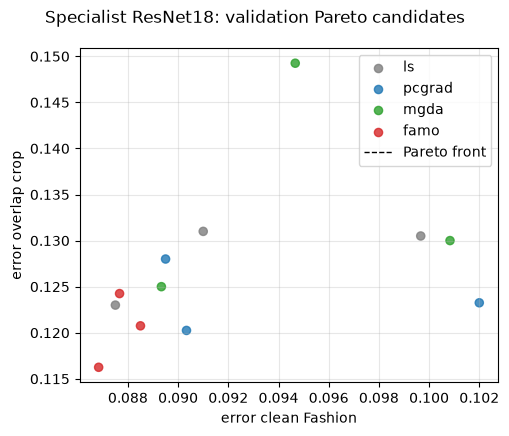

In [34]:
spec_prefs = [[0.5, 0.5], [0.8, 0.2], [0.2, 0.8]]
spec_res = pareto_explore(spec_run, CFG['METHODS'], spec_prefs, 'specialist')
spec_res = pareto_expand(spec_res, spec_run, CFG['EXPAND_ROUNDS'], 'specialist')
mask = plot_pareto(spec_res, ['clean Fashion', 'overlap crop'], 'Specialist ResNet18: validation Pareto candidates')

In [35]:
# Pick a non-dominated specialist with lowest mean validation error.
front = [r for r, ok in zip(spec_res, mask) if ok]
best_spec = min(front, key=lambda r: np.mean(r['err']))
print('selected specialist:', best_spec['method'], np.round(best_spec['pref'], 2),
      'validation error (clean, overlap):', np.round(best_spec['err'], 4))
specialist = MTLNet('resnet18', 2).to(dev)
specialist.load_state_dict(best_spec['state']); specialist.eval()
print('selected specialist TEST error (clean, overlap):', np.round(spec_eval(specialist, 'test'), 4))

selected specialist: famo [0.8 0.2] validation error (clean, overlap): [0.0868 0.1162]
selected specialist TEST error (clean, overlap): [0.0891 0.1306]


## 6. Stage 2: Specialist soft labels for stacked composites
For each of the two known training slots, take the 28×28 **oracle crop** from the stacked image, center it on a 36×36 canvas, and run both heads of the selected specialist. Average the two temperature-scaled softmax distributions to form teacher soft labels.

Oracle positions are **only used to generate teacher targets**, not provided to the generalist at inference. The generalist sees the full composite only. The fixed slot geometry and strong item overlap still make this a synthetic benchmark, not general object detection.

In [36]:
Tkd = CFG['T_KD']

In [37]:
def teacher_probs(X, P, temp):
    soft_slots = []
    for k in range(K):
        crops = as_dev(crop_pad(X, P, k))
        head_probs = predict(specialist, crops, temp=temp)  # two heads, each (n, 10)
        soft_slots.append(torch.stack(head_probs).mean(0))
    return torch.stack(soft_slots, dim=1)  # CPU: (n, 2, 10)

In [38]:
soft_t = teacher_probs(Xg_tr, Pg_tr, temp=Tkd).to(dev)
assert soft_t.shape == (len(Xg_tr), K, 10)

In [39]:
# Diagnostic: training soft labels can be checked against known synthetic labels,
# but their hard labels MUST NOT enter student CE except through lab_mask.
teach_acc_tr = (soft_t.argmax(-1) == Yg_tr_t).float().mean(0)
print('teacher pseudo-label train accuracy per slot:', teach_acc_tr.cpu().numpy().round(4))

teacher pseudo-label train accuracy per slot: [0.8776 0.892 ]


In [40]:
# Teacher comparison uses actual class probabilities (T=1) on validation and test.
val_teacher = teacher_probs(Xg_val, Pg_val, temp=1.0)
teacher_val_err = (1 - (val_teacher.argmax(-1) == torch.from_numpy(Yg_val)).float().mean(0)).numpy()
print('teacher validation error (oracle crops):', teacher_val_err.round(4))

teacher validation error (oracle crops): [0.1245 0.118 ]


In [41]:
# Fixed, reproducible mask across all student methods/preference runs.
g = torch.Generator().manual_seed(123)
lab_mask = (torch.rand(len(Xg_tr), generator=g) < CFG['LABELED_FRAC']).to(dev)
print('hard-labeled stacked train images:', int(lab_mask.sum()), '/', len(lab_mask))

hard-labeled stacked train images: 1053 / 20000


## 7. Stage 3: Multi-Fashion-MNIST generalist ResNet50 (2 tasks)
The student consumes the **entire stacked 36×36 Fashion composite** and predicts two labels (top-left and bottom-right).

Per-task loss = `LAM * T_KD² * KL(teacher_T || student_T) + (1−LAM) * CE` **only on the labeled part of that minibatch**. Evaluation of Pareto candidates uses held-out validation composites, not the final test set.

In [42]:
def make_gen_loss(lam):
    def gen_loss_fn(model, idx):
        out = model(prep(Xg_tr_t[idx]))
        labeled = lab_mask[idx]
        losses = []
        for k in range(K):
            kd = F.kl_div(F.log_softmax(out[k] / Tkd, -1), soft_t[idx, k],
                          reduction='batchmean') * (Tkd ** 2)
            ce = (F.cross_entropy(out[k][labeled], Yg_tr_t[idx, k][labeled])
                  if labeled.any() else out[k].sum() * 0)
            losses.append(lam * kd + (1 - lam) * ce)
        return losses
    return gen_loss_fn

In [43]:
def gen_eval(model, split='val'):
    X, Y = (Xg_val_t, Yg_val_t) if split == 'val' else (Xg_te_t, Yg_te_t)
    probs = predict(model, X)
    return [1 - (probs[k].argmax(1).to(dev) == Y[:, k]).float().mean().item()
            for k in range(K)]

In [44]:
def gen_run(method, pref, lam=None, eval_test=False):
    set_seed(CFG['SEED'])
    m = MTLNet('resnet50', K).to(dev)
    train_mtl(m, make_gen_loss(CFG['LAM'] if lam is None else lam),
              len(Xg_tr_t), K, method, pref, CFG['GEN_EPOCHS'])
    result = dict(err=gen_eval(m, 'val'))
    if eval_test:
        result['test_err'] = gen_eval(m, 'test')
    return result

[generalist] ls      pref=[0.5 0.5] err=[0.1465 0.14  ]  (32s)
[generalist] ls      pref=[0.6 0.4] err=[0.1475 0.1405]  (31s)
[generalist] ls      pref=[0.4 0.6] err=[0.141  0.1335]  (31s)
[generalist] pcgrad  pref=[0.5 0.5] err=[0.142  0.1335]  (73s)
[generalist] pcgrad  pref=[0.6 0.4] err=[0.151  0.1405]  (72s)
[generalist] pcgrad  pref=[0.4 0.6] err=[0.154 0.14 ]  (71s)
[generalist] mgda    pref=[0.5 0.5] err=[0.149  0.1465]  (123s)
[generalist] mgda    pref=[0.6 0.4] err=[0.1485 0.138 ]  (123s)
[generalist] mgda    pref=[0.4 0.6] err=[0.1405 0.153 ]  (122s)
[generalist] famo    pref=[0.5 0.5] err=[0.1445 0.1375]  (41s)
[generalist] famo    pref=[0.6 0.4] err=[0.143 0.136]  (42s)
[generalist] famo    pref=[0.4 0.6] err=[0.1395 0.1335]  (41s)
[generalist] expansion round 1: 0 new preference points


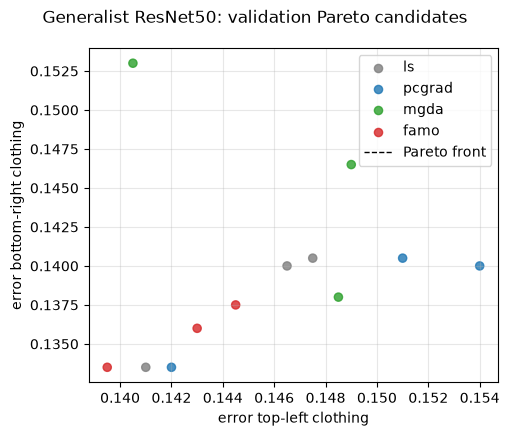

In [45]:
gen_prefs = make_prefs(K, CFG['N_PREF_EXTRA'])
gen_res = pareto_explore(gen_run, CFG['METHODS'], gen_prefs, 'generalist')
gen_res = pareto_expand(gen_res, gen_run, CFG['EXPAND_ROUNDS'], 'generalist')
gmask = plot_pareto(gen_res, ['top-left clothing', 'bottom-right clothing'],
                    'Generalist ResNet50: validation Pareto candidates')

## 8. Baselines, selection, and final test reporting
Select one student configuration from the validation non-dominated set, then deterministically retrain that configuration for final test scoring. A labeled-only student (`LAM=0`) is the comparison baseline. The teacher's *oracle crops* make its accuracy **not directly comparable** to full-image student accuracy.

In [47]:
# Baseline for model-selection comparison (validation only).
base = gen_run('ls', [1.0 / K] * K, lam=0.0)
print('baseline (5% labeled-only) VAL error:', np.round(base['err'], 4))

baseline (5% labeled-only) VAL error: [0.3005 0.306 ]


In [48]:
# Per-method validation candidates.
rows = []
for method in CFG['METHODS']:
    candidates = [r for r in gen_res if r['method'] == method]
    b = min(candidates, key=lambda r: np.mean(r['err']))
    rows.append(dict(method=method, split='val', mean_err=float(np.mean(b['err'])),
                     **{f'slot{k}': b['err'][k] for k in range(K)},
                     pref=np.round(b['pref'], 2).tolist()))
rows.append(dict(method='baseline labeled-only', split='val', mean_err=float(np.mean(base['err'])),
                 **{f'slot{k}': base['err'][k] for k in range(K)}))
rows.append(dict(method='specialist teacher (oracle)', split='val', mean_err=float(teacher_val_err.mean()),
                 **{f'slot{k}': teacher_val_err[k] for k in range(K)}))
print('VALIDATION summary:')
print(pd.DataFrame(rows).round(4).to_string(index=False))

VALIDATION summary:
                     method split  mean_err  slot0  slot1       pref
                         ls   val    0.1372 0.1410 0.1335 [0.4, 0.6]
                     pcgrad   val    0.1377 0.1420 0.1335 [0.5, 0.5]
                       mgda   val    0.1432 0.1485 0.1380 [0.6, 0.4]
                       famo   val    0.1365 0.1395 0.1335 [0.4, 0.6]
      baseline labeled-only   val    0.3032 0.3005 0.3060        NaN
specialist teacher (oracle)   val    0.1212 0.1245 0.1180        NaN


In [49]:
selected_candidates = [r for r, ok in zip(gen_res, gmask) if ok]
selected = min(selected_candidates, key=lambda r: np.mean(r['err']))
print('selected generalist by VAL:', selected['method'], np.round(selected['pref'], 2))

selected generalist by VAL: famo [0.4 0.6]


In [50]:
# Deterministic retraining with the chosen settings; do not choose parameters using test metrics.
final_gen = gen_run(selected['method'], selected['pref'], eval_test=True)
final_base = gen_run('ls', [1.0 / K] * K, lam=0.0, eval_test=True)
teacher_test_probs = teacher_probs(Xg_te, Pg_te, temp=1.0)
teacher_test_err = (1 - (teacher_test_probs.argmax(-1) == torch.from_numpy(Yg_te)).float().mean(0)).numpy()

In [51]:
final_rows = []
for name, errors in [('selected generalist (full image)', final_gen['test_err']),
                     ('baseline labeled-only (full image)', final_base['test_err']),
                     ('specialist teacher (oracle crops)', teacher_test_err)]:
    final_rows.append(dict(model=name, mean_test_err=float(np.mean(errors)),
                           **{f'slot{k}': float(errors[k]) for k in range(K)}))
print('FINAL TEST summary (lower is better):')
print(pd.DataFrame(final_rows).round(4).to_string(index=False))

FINAL TEST summary (lower is better):
                             model  mean_test_err  slot0  slot1
  selected generalist (full image)         0.1472 0.1538 0.1406
baseline labeled-only (full image)         0.3071 0.2980 0.3162
 specialist teacher (oracle crops)         0.1293 0.1384 0.1202


In [52]:
E = np.array([r['err'] for r in gen_res]); gm = nondominated(E)
print('VALIDATION non-dominated points per method:',
      {m: int(sum(1 for r, ok in zip(gen_res, gm) if ok and r['method'] == m))
       for m in CFG['METHODS']})

VALIDATION non-dominated points per method: {'ls': 0, 'pcgrad': 0, 'mgda': 0, 'famo': 1}


### Notes / reproducibility
- **GitHub sources**: Original Fashion-MNIST at https://github.com/zalandoresearch/fashion-mnist ; Multi-Fashion implementation (`mf`) at https://github.com/ruchtem/cosmos ; related MOO benchmark at https://github.com/ruchtem/moo-mtl .
- **Not precomputed GitHub dataset**: `make_multi` creates a new Fashion-only 36×36 overlapping **two-object** synthetic dataset with additive clipped compositing, fixed spatial slots, and reproducible seeds. If you need to reproduce a particular paper's exact benchmark scores, load **its** official Multi-Fashion data files and splits instead.
- **Specialist**: two supervised objectives using source-train Fashion-MNIST labels: clean single items and overlap-contaminated oracle crops. Select the non-dominated specialist using *validation* only.
- **Semi-supervised**: teacher soft targets are computed for all student-train composites; ground-truth labels enter student CE for `LABELED_FRAC` only (5% by default). The teacher uses oracle positions during pseudo-label generation, but the student never receives the crop positions.
- **Pareto**: preference exploration/expansion and LS, PCGrad, MGDA, FAMO retained from the original notebook. Values on plots are validation errors; final report uses the independent test set.
- **Compute**: ResNet50 / PCGrad / MGDA / FAMO exploration is expensive. Set the optional `CFG.update(...)` quick mode in cell 1 for a functionality check on CPU. For full training, use a GPU.
- **Interpretation**: closely related tasks can have a common good solution; a scatter of non-dominated points does not automatically imply a meaningful Pareto front. See https://github.com/ruchtem/moo-mtl .
